# Dynesty–pocoMC Single-Sérsic Validation

This notebook performs the first controlled astronomical comparison between the
BayMorph Dynesty and pocoMC backends.

## Scientific objective

Both samplers receive exactly the same:

- simulated galaxy image;
- PSF;
- Gaussian noise realization;
- `ImageInferenceProblem`;
- model parameterization;
- priors;
- likelihood implementation.

The comparison separates four questions:

1. Do both backends recover compatible posterior distributions?
2. Are the generative parameters consistent with the inferred posterior?
3. Do the native marginal-likelihood estimates agree?
4. How do likelihood evaluations and wall-clock cost compare?

This is an **integration diagnostic**, not yet the definitive BayMorph sampler
benchmark. A single fixed dataset and one sampler seed are used first so that
the result can be inspected visually before repeated-run validation.


In [1]:
from __future__ import annotations

from importlib.metadata import version
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from baymorph.fitting import DynestyFitter, Parameter, ParameterSet, PocoMCFitter
from baymorph.fitting.image_problem import ImageInferenceProblem
from baymorph.likelihood import GaussianImageLikelihood
from baymorph.models import SersicModel
from baymorph.simulation import GaussianPSF
from baymorph.simulation.psf import convolve_with_psf

from IPython.display import display as ipy_display

print("BayMorph environment")
for package in ("baymorph", "dynesty", "pocomc", "numpy", "scipy"):
    try:
        print(f"{package:10s} {version(package)}")
    except Exception:
        print(f"{package:10s} local/unavailable metadata")


BayMorph environment
baymorph   0.3.0
dynesty    3.1.0
pocomc     1.2.6
numpy      2.4.6
scipy      1.17.1


## 1. Controlled observation

The background is fixed to zero in this first experiment. This deliberately
removes background degeneracy so that the first comparison isolates the
morphological inference machinery.

The model has seven free parameters: total flux, effective radius, Sérsic
index, axis ratio, position angle, and centroid.


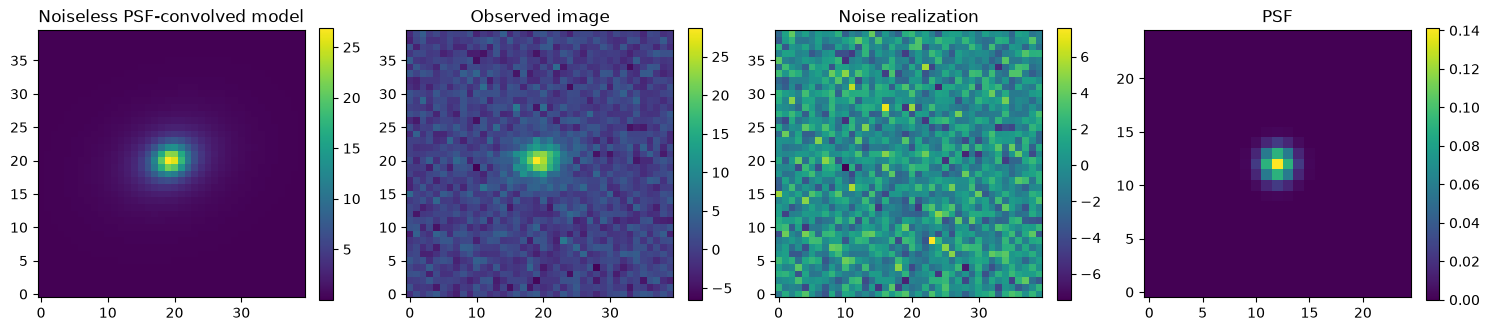

In [2]:
SHAPE = (40, 40)
NOISE_SIGMA = 2.0
PSF_FWHM = 2.5
DATA_SEED = 314159
SAMPLER_SEED = 42

TRUTH = {
    "flux": 1200.0,
    "re": 5.0,
    "n": 2.5,
    "q": 0.72,
    "theta": 0.35,
    "x0": 19.4,
    "y0": 20.1,
}

psf = GaussianPSF(fwhm=PSF_FWHM)

truth_model = SersicModel(**TRUTH)
truth_unconvolved = truth_model.render(shape=SHAPE)
truth_image = convolve_with_psf(truth_unconvolved, psf)

rng = np.random.default_rng(DATA_SEED)
noise_realization = rng.normal(0.0, NOISE_SIGMA, size=SHAPE)
data = truth_image + noise_realization

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
images = (
    (truth_image, "Noiseless PSF-convolved model"),
    (data, "Observed image"),
    (noise_realization, "Noise realization"),
    (psf.kernel(), "PSF"),
)
for ax, (image, title) in zip(axes, images, strict=True):
    display = ax.imshow(image, origin="lower")
    ax.set_title(title)
    plt.colorbar(display, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


## 2. Shared inference problem

The same `CountingImageInferenceProblem` instance is used conceptually by both
backends. The subclass only counts likelihood evaluations; it does not alter
the likelihood.


In [3]:
parameters = ParameterSet(
    [
        Parameter("flux", 600.0, 1800.0),
        Parameter("re", 2.0, 9.0),
        Parameter("n", 0.5, 6.0),
        Parameter("q", 0.4, 1.0),
        Parameter("theta", -0.5 * np.pi, 0.5 * np.pi),
        Parameter("x0", 17.0, 23.0),
        Parameter("y0", 17.0, 23.0),
    ]
)

likelihood = GaussianImageLikelihood(
    data=data,
    noise=NOISE_SIGMA,
    include_normalization=True,
)

def model_factory(*, flux, re, n, q, theta, x0, y0):
    return SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=q,
        theta=theta,
        x0=x0,
        y0=y0,
    )

class CountingImageInferenceProblem(ImageInferenceProblem):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.ncall = 0

    def log_likelihood(self, theta):
        self.ncall += 1
        return super().log_likelihood(theta)

    def reset_counter(self):
        self.ncall = 0

problem = CountingImageInferenceProblem(
    model_factory=model_factory,
    parameters=parameters,
    likelihood=likelihood,
    psf=psf,
)

truth_vector = np.asarray([TRUTH[name] for name in parameters.names])
truth_logl = problem.log_likelihood(truth_vector)
problem.reset_counter()

prior_table = pd.DataFrame(
    {
        "parameter": parameters.names,
        "truth": [TRUTH[name] for name in parameters.names],
        "lower": [parameter.lower for parameter in parameters.parameters],
        "upper": [parameter.upper for parameter in parameters.parameters],
    }
)

ipy_display(prior_table)
print(f"log L at generative parameters = {truth_logl:.6f}")


,parameter,truth,lower,upper
0,flux,1200.00,600.000000,1800.000000
1,re,5.00,2.000000,9.000000
2,n,2.50,0.500000,6.000000
3,q,0.72,0.400000,1.000000
4,theta,0.35,-1.570796,1.570796
5,x0,19.40,17.000000,23.000000
6,y0,20.10,17.000000,23.000000


log L at generative parameters = -3382.173011


## 3. Dynesty

The configuration is intentionally conservative and serial. Parallelism is
excluded from this first comparison.


In [4]:
dynesty_fitter = DynestyFitter(problem=problem)

problem.reset_counter()
start = perf_counter()

dynesty_result = dynesty_fitter.run(
    nlive=500,
    sample="auto",
    bound="multi",
    dlogz=0.05,
    print_progress=True,
    n_processes=1,
    seed=SAMPLER_SEED,
    progress_label="single-Sersic / Dynesty",
)

dynesty_runtime = perf_counter() - start
dynesty_ncall = problem.ncall

print(f"Dynesty logZ     = {dynesty_result.final_logz:.6f}")
print(f"Dynesty logZerr  = {float(np.asarray(dynesty_result.logzerr)[-1]):.6f}")
print(f"Dynesty ncall    = {dynesty_ncall}")
print(f"Dynesty runtime  = {dynesty_runtime:.3f} s")



────────────────────────────────────────────────────
Running Dynesty fit: single-Sersic / Dynesty
ndim=7, nlive=500, sample=auto, bound=multi
────────────────────────────────────────────────────


────────────────────────────────────────────────────
Completed Dynesty fit: single-Sersic / Dynesty
logZ=-3395.73
logZerr=0.191261
ncall=120569
────────────────────────────────────────────────────
Dynesty logZ     = -3395.729246
Dynesty logZerr  = 0.191261
Dynesty ncall    = 120569
Dynesty runtime  = 158.144 s


## 4. pocoMC

The first astronomical run uses the same serial CPU strategy as the synthetic
validation. Vectorization and multiprocessing remain disabled until scientific
equivalence is established.


In [5]:
pocomc_fitter = PocoMCFitter(
    problem=problem,
    config={
        "name": "pocomc",
        "n_effective": 512,
        "n_active": 256,
        "n_total": 4096,
        "n_evidence": 4096,
        "pytorch_threads": 1,
        "precondition": True,
        "dynamic": True,
        "metric": "ess",
        "mcmc_sampler": "tpcn",
    },
)

problem.reset_counter()
start = perf_counter()

pocomc_result = pocomc_fitter.run(
    print_progress=True,
    n_processes=1,
    seed=SAMPLER_SEED,
    progress_label="single-Sersic / pocoMC",
)

pocomc_runtime = perf_counter() - start
pocomc_ncall = problem.ncall

print(f"pocoMC logZ      = {pocomc_result.final_logz:.6f}")
print(f"pocoMC logZerr   = {float(np.asarray(pocomc_result.logzerr)[-1]):.6f}")
print(f"pocoMC ncall     = {pocomc_ncall}")
print(f"pocoMC runtime   = {pocomc_runtime:.3f} s")



────────────────────────────────────────────────────
Running pocoMC fit: single-Sersic / pocoMC
ndim=7, n_effective=512, n_active=256, flow=nsf6
────────────────────────────────────────────────────


Iter: 35it [01:46,  3.04s/it, beta=1, calls=43776, ESS=3918, logZ=-3.4e+3, logP=-3.4e+3, acc=0.785, steps=3, eff=1]     

────────────────────────────────────────────────────
Completed pocoMC fit: single-Sersic / pocoMC
logZ=-3395.68
logZerr=0.00892176
ncall=39680
────────────────────────────────────────────────────
pocoMC logZ      = -3395.676039
pocoMC logZerr   = 0.008922
pocoMC ncall     = 43776
pocoMC runtime   = 107.535 s


## 5. Posterior summaries

The generative value is not the posterior expectation for one noisy dataset.
Therefore the truth offsets below are diagnostics, not a criterion that the
posterior must be centered exactly on the injected parameters.


In [7]:
def weighted_summary(result):
    rows = []
    for index, name in enumerate(result.parameter_names):
        values = result.samples[:, index]
        weights = result.weights
        mean = np.average(values, weights=weights)
        variance = np.average((values - mean) ** 2, weights=weights)
        summary = result.summary(name)
        rows.append(
            {
                "parameter": name,
                "mean": mean,
                "std": np.sqrt(variance),
                "median": summary["median"],
                "q16": summary["q16"],
                "q84": summary["q84"],
            }
        )
    return pd.DataFrame(rows).set_index("parameter")

dynesty_summary = weighted_summary(dynesty_result)
pocomc_summary = weighted_summary(pocomc_result)

comparison = pd.DataFrame(index=parameters.names)
comparison["truth"] = [TRUTH[name] for name in parameters.names]
comparison["dynesty_mean"] = dynesty_summary["mean"]
comparison["dynesty_std"] = dynesty_summary["std"]
comparison["pocomc_mean"] = pocomc_summary["mean"]
comparison["pocomc_std"] = pocomc_summary["std"]
comparison["mean_difference_sigma"] = (
    comparison["pocomc_mean"] - comparison["dynesty_mean"]
) / np.sqrt(
    comparison["pocomc_std"] ** 2 + comparison["dynesty_std"] ** 2
)
comparison["dynesty_truth_offset_sigma"] = (
    comparison["dynesty_mean"] - comparison["truth"]
) / comparison["dynesty_std"]
comparison["pocomc_truth_offset_sigma"] = (
    comparison["pocomc_mean"] - comparison["truth"]
) / comparison["pocomc_std"]

ipy_display(comparison)


,truth,dynesty_mean,dynesty_std,pocomc_mean,pocomc_std,mean_difference_sigma,dynesty_truth_offset_sigma,pocomc_truth_offset_sigma
flux,1200.00,1133.755691,119.377230,1130.764132,120.023114,-0.017672,-0.554916,-0.576854
re,5.00,4.816327,0.869086,4.801860,0.853461,-0.011877,-0.211340,-0.232161
n,2.50,2.563212,0.521170,2.544486,0.514412,-0.025573,0.121289,0.086479
q,0.72,0.652474,0.053573,0.650910,0.051826,-0.020982,-1.260453,-1.333122
theta,0.35,0.165918,0.092692,0.165877,0.091789,-0.000316,-1.985960,-2.005932
x0,19.40,19.408748,0.068738,19.407425,0.067354,-0.013745,0.127264,0.110241
y0,20.10,20.113278,0.059857,20.112344,0.057134,-0.011282,0.221820,0.216054


## 6. Marginal posterior comparison


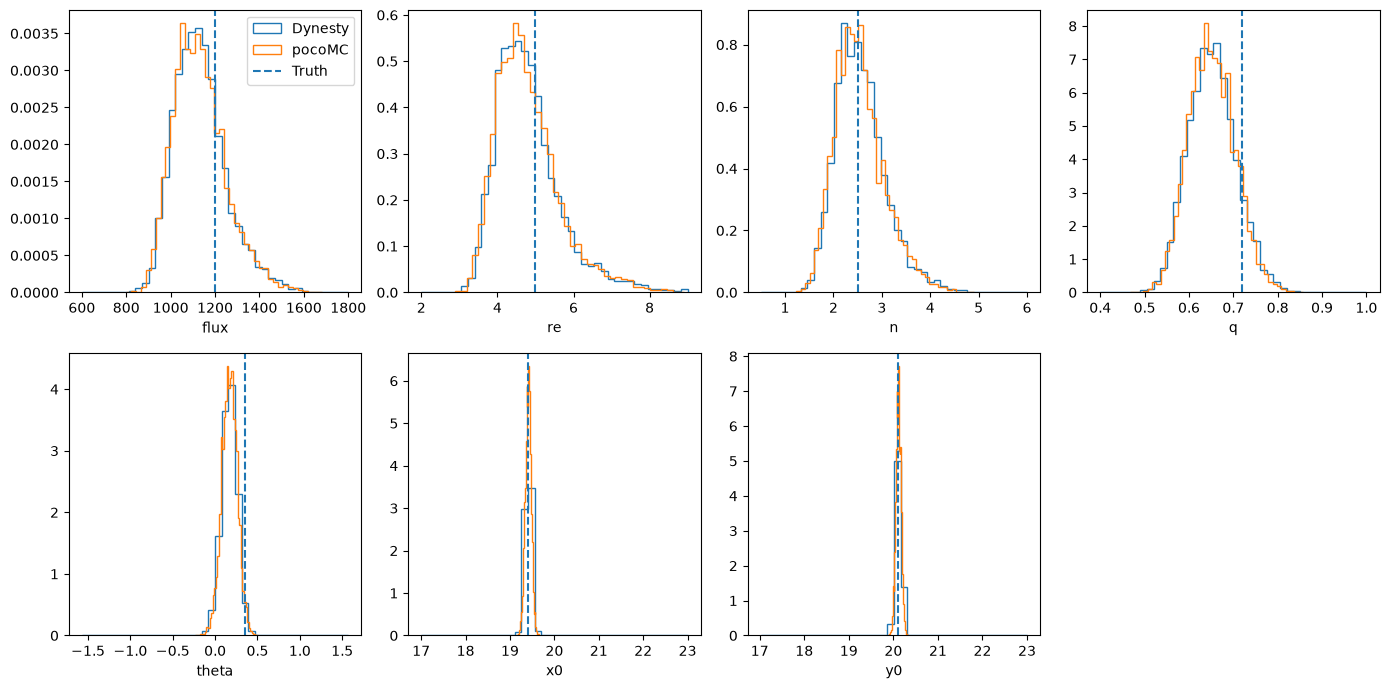

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()

for index, name in enumerate(parameters.names):
    ax = axes[index]

    ax.hist(
        dynesty_result.samples[:, index],
        bins=40,
        weights=dynesty_result.weights,
        density=True,
        histtype="step",
        label="Dynesty",
    )
    ax.hist(
        pocomc_result.samples[:, index],
        bins=40,
        weights=pocomc_result.weights,
        density=True,
        histtype="step",
        label="pocoMC",
    )
    ax.axvline(TRUTH[name], linestyle="--", label="Truth")
    ax.set_xlabel(name)

axes[-1].axis("off")
axes[0].legend()
plt.tight_layout()
plt.show()


## 7. Image-space posterior diagnostics

The maximum-likelihood sample from each backend is rendered through the same
`ImageInferenceProblem`. Residuals are compared directly in units of the known
pixel noise.


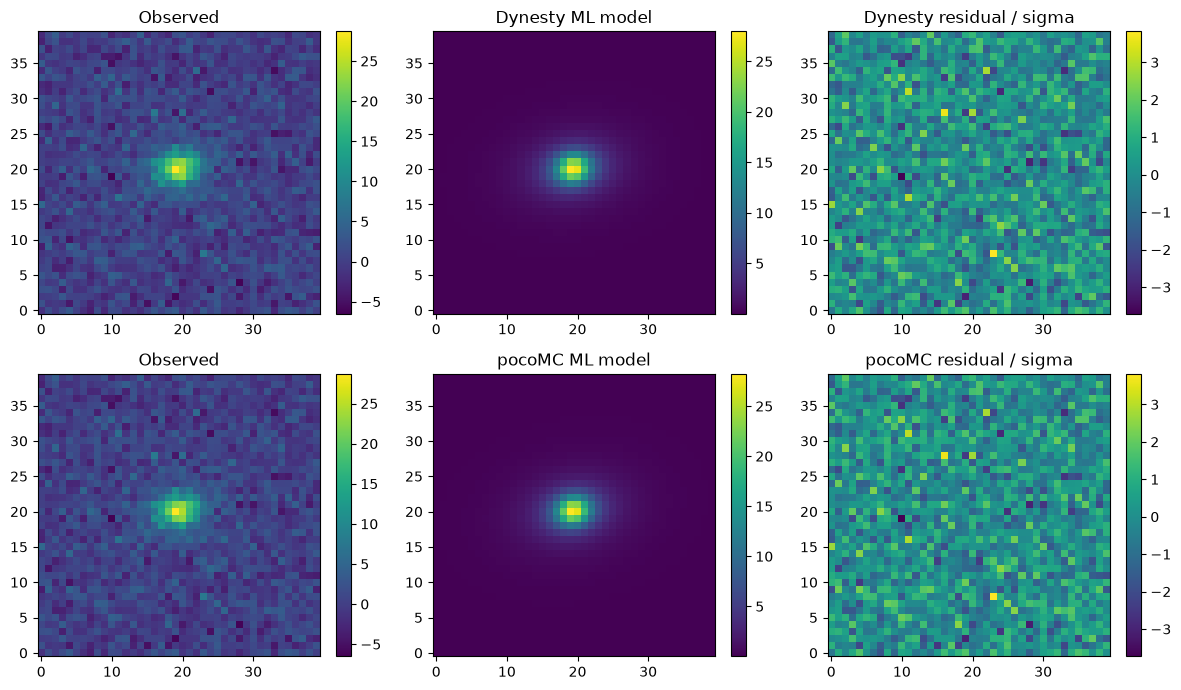

Dynesty residual RMS: 0.998814205307661
pocoMC residual RMS: 0.9989126123359908


In [9]:
dynesty_best_image = problem.render_model(dynesty_result.best_sample)
pocomc_best_image = problem.render_model(pocomc_result.best_sample)

dynesty_residual = (data - dynesty_best_image) / NOISE_SIGMA
pocomc_residual = (data - pocomc_best_image) / NOISE_SIGMA

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

panels = (
    (data, "Observed"),
    (dynesty_best_image, "Dynesty ML model"),
    (dynesty_residual, "Dynesty residual / sigma"),
    (data, "Observed"),
    (pocomc_best_image, "pocoMC ML model"),
    (pocomc_residual, "pocoMC residual / sigma"),
)

for ax, (image, title) in zip(axes.ravel(), panels, strict=True):
    display_image = ax.imshow(image, origin="lower")
    ax.set_title(title)
    plt.colorbar(display_image, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

print(
    "Dynesty residual RMS:",
    float(np.sqrt(np.mean(dynesty_residual**2))),
)
print(
    "pocoMC residual RMS:",
    float(np.sqrt(np.mean(pocomc_residual**2))),
)


## 8. Evidence and computational comparison

No independent high-accuracy evidence reference is available for this image
problem yet. Consequently, agreement between Dynesty and pocoMC is informative,
but neither backend is treated as ground truth.


In [11]:
dynesty_logzerr = float(np.asarray(dynesty_result.logzerr)[-1])
pocomc_logzerr = float(np.asarray(pocomc_result.logzerr)[-1])

performance = pd.DataFrame(
    [
        {
            "backend": "Dynesty",
            "logz": dynesty_result.final_logz,
            "logzerr": dynesty_logzerr,
            "ncall": dynesty_ncall,
            "runtime_seconds": dynesty_runtime,
        },
        {
            "backend": "pocoMC",
            "logz": pocomc_result.final_logz,
            "logzerr": pocomc_logzerr,
            "ncall": pocomc_ncall,
            "runtime_seconds": pocomc_runtime,
        },
    ]
).set_index("backend")

ipy_display(performance)

delta_logz = pocomc_result.final_logz - dynesty_result.final_logz

print(f"Delta logZ (pocoMC - Dynesty) = {delta_logz:.6f}")
print(f"pocoMC / Dynesty ncall ratio  = {pocomc_ncall / dynesty_ncall:.4f}")
print(f"pocoMC / Dynesty time ratio   = {pocomc_runtime / dynesty_runtime:.4f}")


,logz,logzerr,ncall,runtime_seconds
backend,,,,
Dynesty,-3395.729246,0.191261,120569,158.144174
pocoMC,-3395.676039,0.008922,43776,107.535467


Delta logZ (pocoMC - Dynesty) = 0.053207
pocoMC / Dynesty ncall ratio  = 0.3631
pocoMC / Dynesty time ratio   = 0.6800


## 9. Interpretation checklist

Before increasing the number of repetitions, inspect the following:

- Are all marginal posterior distributions compatible between the backends?
- Are any parameters visibly truncated by their priors?
- Is either backend missing posterior structure?
- Are the residual maps statistically comparable?
- Is the native evidence difference small relative to the quoted uncertainties?
- Does pocoMC reduce the number of expensive BayMorph likelihood evaluations?
- Does that reduction, if present, compensate for normalizing-flow overhead?

### Decision rule for the next milestone

If posterior agreement and image residuals are satisfactory, repeat the exact
experiment over multiple sampler seeds while holding the simulated dataset
fixed. That experiment will estimate run-to-run evidence scatter and
computational variability.

Only after sampler repeatability is established should the data realization,
S/N, PSF width, Sérsic index, effective radius, and prior volume be varied.
